# 01 — Distribuições aplicadas a métricas de marketing

> **stats-foundations · Fase 1** — ligando teoria estatística ao que eu já vejo no Meta Ads / Google Ads.

Toda métrica de campanha é uma **variável aleatória**: ela varia por acaso a cada execução.
Saber *qual distribuição a gera* é o que permite construir intervalos de confiança corretos,
dimensionar testes A/B e separar ruído de efeito real.

Neste notebook ligo **três distribuições** a **três métricas reais** de uma campanha sintética:

| Distribuição | Métrica de marketing | Pergunta que responde |
|---|---|---|
| **Bernoulli** | taxa de conversão (lead → cliente) | "este lead converte: sim ou não?" |
| **Poisson** | contagem de cliques/eventos por dia | "quantos cliques cairão hoje?" |
| **Log-normal** | receita por cliente | "quanto este cliente vai gastar?" |

Os dados são **sintéticos mas realistas** (uma campanha fictícia de 60 dias), gerados com `numpy`
para que o notebook seja 100% reprodutível e não exponha dados de cliente.

## Setup

Fixamos a *seed* para reprodutibilidade — qualquer pessoa que rodar o notebook obtém os mesmos números.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

RNG = np.random.default_rng(42)  # seed fixa => resultados reprodutíveis

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})

def brl(x, _=None):  # formata um valor como moeda brasileira (R$) para os eixos
    return f"R$ {x:,.0f}".replace(",", ".")

print("Ambiente pronto. numpy", np.__version__, "| pandas", pd.__version__)

Ambiente pronto. numpy 2.4.6 | pandas 3.0.3


## 1. Bernoulli → taxa de conversão

### Por que Bernoulli modela conversão

Um **ensaio de Bernoulli** é qualquer experimento com **dois resultados**: sucesso (1) ou fracasso (0),
com probabilidade *p* de sucesso. É a distribuição mais simples que existe — e é *exatamente* o formato
de uma conversão:

- cada **lead** que entra no funil é um ensaio;
- ele **converte (1)** ou **não converte (0)**;
- a probabilidade de converter é *p* — a "verdadeira" taxa de conversão da campanha.

A **taxa de conversão** que reporto no dashboard é apenas a **média** desses 0s e 1s, ou seja, uma
*estimativa* de *p* a partir da amostra. Isso muda como eu penso: a taxa observada **não é o número
verdadeiro**, é um chute com incerteza — e essa incerteza diminui conforme o número de leads cresce
(Lei dos Grandes Números). É a base para, mais adiante, calcular intervalos de confiança e tamanho de amostra de teste A/B.

In [2]:
# Campanha fictícia: 2.000 leads, com taxa de conversão "verdadeira" p = 12%
p_verdadeiro = 0.12
n_leads = 2_000

# Cada lead é um ensaio de Bernoulli: 1 = converteu, 0 = não converteu
conversoes = RNG.binomial(n=1, p=p_verdadeiro, size=n_leads)

leads = pd.DataFrame({
    "lead_id": np.arange(1, n_leads + 1),
    "converteu": conversoes,
})

taxa_observada = conversoes.mean()
print(leads.head())
print(f"\nLeads: {n_leads}  |  conversões: {conversoes.sum()}")
print(f"Taxa de conversão observada: {taxa_observada:.3%}  (p verdadeiro = {p_verdadeiro:.1%})")

   lead_id  converteu
0        1          0
1        2          0
2        3          0
3        4          0
4        5          0

Leads: 2000  |  conversões: 246
Taxa de conversão observada: 12.300%  (p verdadeiro = 12.0%)


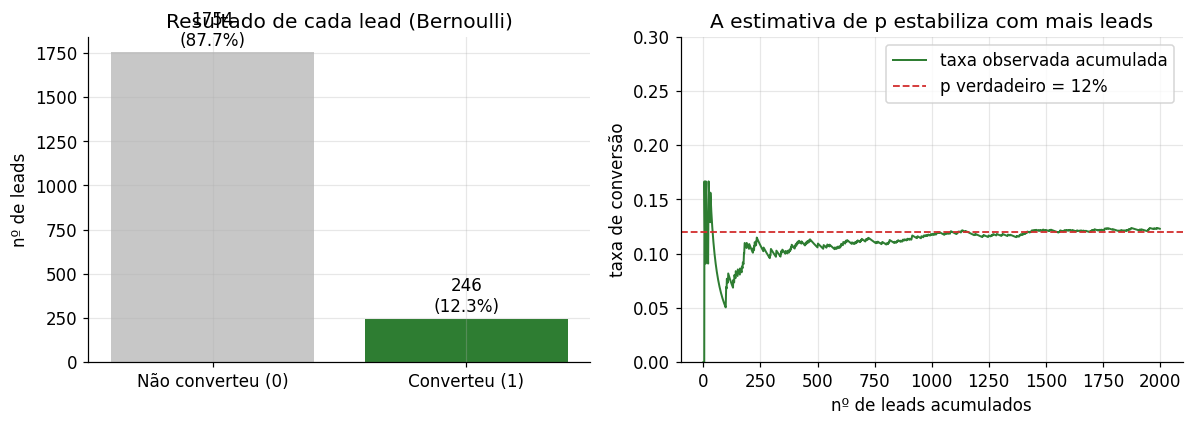

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# (a) contagem: converteu vs não converteu
contagem = leads["converteu"].value_counts().sort_index()
ax1.bar(["Não converteu (0)", "Converteu (1)"], contagem.values,
        color=["#c7c7c7", "#2e7d32"])
for i, v in enumerate(contagem.values):
    ax1.text(i, v + 15, f"{v}\n({v/n_leads:.1%})", ha="center", va="bottom")
ax1.set_title("Resultado de cada lead (Bernoulli)")
ax1.set_ylabel("nº de leads")

# (b) Lei dos Grandes Números: estimativa de p estabiliza conforme entram leads
media_acumulada = np.cumsum(conversoes) / np.arange(1, n_leads + 1)
ax2.plot(media_acumulada, color="#2e7d32", lw=1.3, label="taxa observada acumulada")
ax2.axhline(p_verdadeiro, color="#d32f2f", ls="--", lw=1.2, label=f"p verdadeiro = {p_verdadeiro:.0%}")
ax2.set_title("A estimativa de p estabiliza com mais leads")
ax2.set_xlabel("nº de leads acumulados")
ax2.set_ylabel("taxa de conversão")
ax2.set_ylim(0, 0.30)
ax2.legend()

fig.tight_layout()
plt.show()

## 2. Poisson → contagem de cliques/eventos

### Por que Poisson modela contagens de eventos

A distribuição de **Poisson** descreve **quantos eventos acontecem num intervalo fixo de tempo**,
quando os eventos são independentes e ocorrem a uma taxa média *λ* (lambda). Casa perfeitamente com:

- **cliques por dia** numa campanha;
- impressões, sessões, leads, mensagens no WhatsApp, eventos do pixel...

Cada usuário decide clicar de forma aproximadamente independente, e existe uma taxa média diária *λ*.
A propriedade-chave que torna a Poisson útil (e testável): **a média é aproximadamente igual à variância**
(ambas ≈ *λ*). Se eu observo cliques diários com variância **muito maior** que a média, isso é um sinal
de *superdispersão* — provavelmente algo externo (sazonalidade, picos de orçamento, bot traffic) está
quebrando a hipótese de taxa constante, e eu não deveria tratar o ruído como puramente aleatório.

In [4]:
# 60 dias de campanha, média de 320 cliques/dia
lambda_cliques = 320
n_dias = 60

cliques_por_dia = RNG.poisson(lam=lambda_cliques, size=n_dias)

print(f"Cliques nos primeiros 10 dias: {cliques_por_dia[:10]}")
print(f"\nMédia observada:    {cliques_por_dia.mean():.1f} cliques/dia")
print(f"Variância observada: {cliques_por_dia.var():.1f}")
print("=> média ≈ variância: assinatura de um processo de Poisson "
      f"(λ teórico = {lambda_cliques})")

Cliques nos primeiros 10 dias: [341 362 295 319 299 278 298 316 308 326]

Média observada:    317.3 cliques/dia
Variância observada: 289.2
=> média ≈ variância: assinatura de um processo de Poisson (λ teórico = 320)


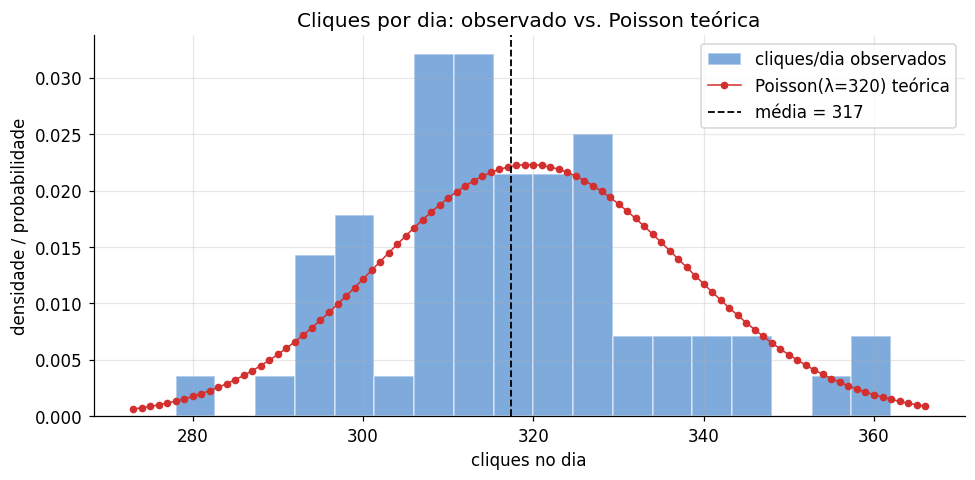

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))

# histograma das contagens diárias observadas (densidade) ...
ax.hist(cliques_por_dia, bins=18, density=True, color="#1565c0", alpha=0.55,
        edgecolor="white", label="cliques/dia observados")

# ... com a função de massa de probabilidade (PMF) teórica de Poisson por cima
x = np.arange(cliques_por_dia.min() - 5, cliques_por_dia.max() + 5)
ax.plot(x, stats.poisson.pmf(x, lambda_cliques), "o-", color="#d32f2f",
        ms=4, lw=1, label=f"Poisson(λ={lambda_cliques}) teórica")

ax.axvline(cliques_por_dia.mean(), color="black", ls="--", lw=1.2,
           label=f"média = {cliques_por_dia.mean():.0f}")
ax.set_title("Cliques por dia: observado vs. Poisson teórica")
ax.set_xlabel("cliques no dia")
ax.set_ylabel("densidade / probabilidade")
ax.legend()
fig.tight_layout()
plt.show()

## 3. Log-normal → receita por cliente

### Por que log-normal modela receita

A **receita por cliente** quase nunca é simétrica como uma curva normal. Ela é **assimétrica à direita**:
a maioria gasta pouco/moderado, e uma cauda longa de poucos clientes gasta *muito*. A distribuição
**log-normal** captura isso — é o que se obtém quando o **logaritmo** da variável é normal.

A intuição de marketing: o gasto de um cliente é resultado de vários fatores que se **multiplicam**
(poder de compra × engajamento × nº de itens × upsell...). Soma de efeitos → Normal; **produto** de
efeitos → **Log-normal**. Consequências práticas que isso me ensina:

- a **média é puxada pela cauda** e fica **acima da mediana** → reportar só a média de ticket engana;
  a **mediana** descreve melhor o "cliente típico";
- por isso modelos e features de receita costumam usar **transformação logarítmica** (`log(receita)`),
  que volta a variável para um formato simétrico e bem-comportado.

Aqui amarro as seções: o número de clientes que geram receita é **exatamente o nº de conversões**
da seção 1 (Bernoulli).

In [6]:
# Receita só existe para quem converteu (amarra com a seção 1)
n_clientes = int(conversoes.sum())

# Log-normal: parametrizada pela mediana (=exp(mu)) e dispersão sigma (em log)
mediana_alvo = 450.0          # ticket mediano ~ R$ 450
mu = np.log(mediana_alvo)     # média do log
sigma = 0.6                   # dispersão no espaço log (cauda à direita)

receita = RNG.lognormal(mean=mu, sigma=sigma, size=n_clientes)

clientes = pd.DataFrame({"cliente_id": np.arange(1, n_clientes + 1),
                         "receita": receita.round(2)})

print(clientes.head())
print(f"\nClientes pagantes: {n_clientes}")
print(f"Receita MÉDIA (ticket médio): {brl(receita.mean())}")
print(f"Receita MEDIANA (cliente típico): {brl(np.median(receita))}")
print(f"Receita total da campanha: {brl(receita.sum())}")
print(f"\nObservação: média ({brl(receita.mean())}) > mediana "
      f"({brl(np.median(receita))}) por causa da cauda à direita.")

   cliente_id  receita
0           1   476.28
1           2   720.58
2           3   758.80
3           4   277.70
4           5   152.07

Clientes pagantes: 246
Receita MÉDIA (ticket médio): R$ 563
Receita MEDIANA (cliente típico): R$ 476
Receita total da campanha: R$ 138.397

Observação: média (R$ 563) > mediana (R$ 476) por causa da cauda à direita.


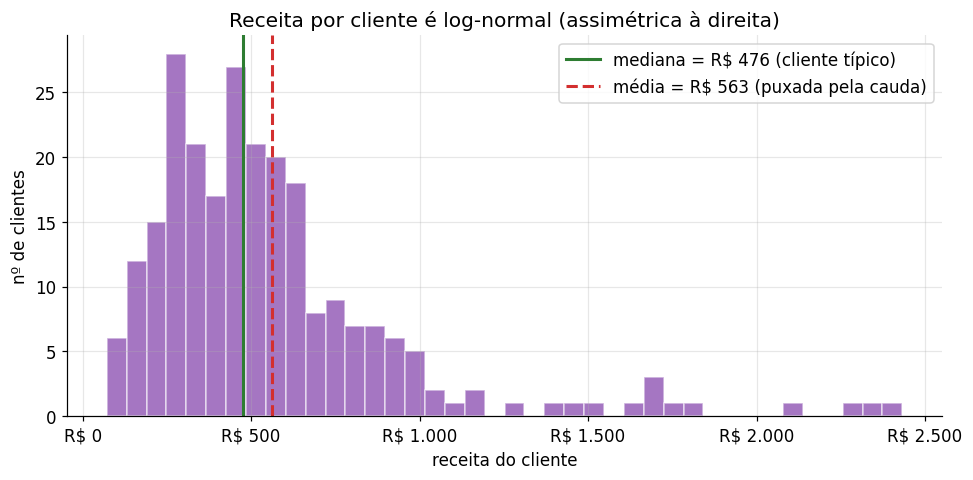

In [7]:
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(9, 4.5))

ax.hist(receita, bins=40, color="#6a1b9a", alpha=0.6, edgecolor="white")
ax.axvline(np.median(receita), color="#2e7d32", ls="-", lw=2,
           label=f"mediana = {brl(np.median(receita))} (cliente típico)")
ax.axvline(receita.mean(), color="#d32f2f", ls="--", lw=2,
           label=f"média = {brl(receita.mean())} (puxada pela cauda)")

ax.set_title("Receita por cliente é log-normal (assimétrica à direita)")
ax.set_xlabel("receita do cliente")
ax.set_ylabel("nº de clientes")
ax.xaxis.set_major_formatter(FuncFormatter(brl))
ax.legend()
fig.tight_layout()
plt.show()

## Resumo — distribuição → métrica → o que aprendi

| Distribuição | Métrica | Propriedade-chave | Implicação prática no tráfego |
|---|---|---|---|
| **Bernoulli(p)** | conversão (0/1) | média dos 0s e 1s = estimativa de *p* | a taxa de conversão é um *chute* com incerteza; quanto mais leads, mais confiável → base de A/B test e tamanho de amostra |
| **Poisson(λ)** | cliques/eventos por dia | média ≈ variância | se a variância "explode" acima da média, há fator externo (sazonalidade/bot) — não é só acaso |
| **Log-normal(μ,σ)** | receita por cliente | assimétrica; média > mediana | reportar só ticket *médio* engana; usar **mediana** e modelar **log(receita)** |

**Próximos passos (Fase 1):** a partir destas distribuições, construir **intervalos de confiança**
para a taxa de conversão, calcular **poder estatístico / tamanho mínimo de amostra** antes de um
teste A/B, e tratar **correção para múltiplos testes** quando comparo várias métricas ao mesmo tempo.